# Bone Fracture Specialist -- CliniqAI

**Dataset:** [Fracture Multi-Region X-ray Data](https://www.kaggle.com/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data)
-- pre-split train/val/test, binary labels (fractured / not fractured), multiple
anatomical regions (elbow, hand, shoulder, etc.)

**Config (matches your other specialists):** EfficientNet-B0, batch size 32, lr 1e-3,
weight decay 1e-4, early stopping patience 10, 224x224 input, `num_workers=0` (Windows).

**Note on this rewrite:** originally built by Roneet for his machine (RTX 5050, `D:\CliniqAI`
paths, fixed 20-epoch schedule, no early stopping). Adjusted here to your paths and your
established training recipe, and trimmed to match the structure of your other specialist
notebooks (breast histology, skin lesion) -- dropped the RTX 50-series GPU compatibility
workaround (not needed on your 4050), the multi-dataset fallback list, EDA plot file-saving,
the full ROC curve section, and Grad-CAM (deferred project-wide to the explainability phase,
same as your other specialists).

**Critical fix included:** a corrupted-image cleaning step before training. The original run
failed with `OSError: image file is truncated` -- a handful of files in this dataset are
partial/corrupted downloads. This notebook scans and removes them before `ImageFolder` ever
sees them, instead of crashing mid-epoch.


## 1. Session setup

In [8]:
import os
import sys
import time
import random
import subprocess
from pathlib import Path

PROJECT_ROOT = r"E:\programming\CliniqAI"
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)

print("Working directory:", os.getcwd())

Working directory: E:\programming\CliniqAI


## 2. Dataset paths and download

In [9]:
DATA_ROOT = Path("data/raw/bone_fracture")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

KAGGLE_DATASET = "bmadushanirodrigo/fracture-multi-region-x-ray-data"

if not any(DATA_ROOT.iterdir()):
    subprocess.run([
        "kaggle", "datasets", "download",
        "-d", KAGGLE_DATASET,
        "-p", str(DATA_ROOT),
        "--unzip"
    ], check=True)
    print("Download complete.")
else:
    print("Data already present, skipping download.")

Data already present, skipping download.


## 3. Detect folder layout

This dataset ships pre-split into train/val/test, each with class subfolders. Some Kaggle
mirrors wrap this inside one extra folder (e.g. `bone_fracture_binary_classification/`) --
this cell checks the top level first, then automatically descends one level if that's where
the actual split folders turn out to be.

In [10]:
def find_presplit_root(root: Path):
    """Recursively searches for a directory containing train/val/test subfolders,
    regardless of how many levels of nesting the Kaggle mirror wraps around it."""
    for candidate in [root] + [d for d in root.rglob("*") if d.is_dir()]:
        subdirs = {d.name.lower(): d for d in candidate.iterdir() if d.is_dir()}
        if all(k in subdirs for k in ["train", "val", "test"]) or \
           all(k in subdirs for k in ["train", "valid", "test"]):
            return candidate, subdirs
    return None, None

SPLIT_ROOT, possible_split_dirs = find_presplit_root(DATA_ROOT)
has_presplit = SPLIT_ROOT is not None

print(f"Pre-split train/val/test folders detected: {has_presplit}")
if has_presplit:
    print(f"Found under: {SPLIT_ROOT}")
    print(f"Split folders: {list(possible_split_dirs.keys())}")
else:
    print("No train/val/test structure found anywhere under DATA_ROOT.")
    raise RuntimeError(
        "Couldn't find train/val/test at any depth. "
        "Check the extracted folder structure with: list(DATA_ROOT.rglob('*'))"
    )

def find_split_dir(name_options):
    for name in name_options:
        if name in possible_split_dirs:
            return possible_split_dirs[name]
    return None

train_dir = find_split_dir(["train"])
val_dir = find_split_dir(["val", "valid"])
test_dir = find_split_dir(["test"])

print(f"train_dir: {train_dir}")
print(f"val_dir:   {val_dir}")
print(f"test_dir:  {test_dir}")

Pre-split train/val/test folders detected: True
Found under: data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification
Split folders: ['test', 'train', 'val']
train_dir: data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification\train
val_dir:   data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification\val
test_dir:  data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification\test


## 4. Clean corrupted/truncated images

Scans every image under all three splits and removes any that fail to fully decode. This is
what fixes the `OSError: image file is truncated` crash -- run this once before building the
datasets, not after.

In [11]:
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True  # safety net for borderline-recoverable files

def is_valid_image(path: Path) -> bool:
    try:
        with Image.open(path) as img:
            img.load()  # forces a full decode -- this is what actually catches truncation
        return True
    except Exception:
        return False

def clean_corrupted_images(root: Path):
    all_images = [
        p for p in root.rglob("*")
        if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp")
    ]
    print(f"Scanning {len(all_images)} images under {root} ...")

    bad_files = []
    for i, path in enumerate(all_images):
        if not is_valid_image(path):
            bad_files.append(path)
        if (i + 1) % 2000 == 0:
            print(f"  checked {i + 1}/{len(all_images)}...")

    for bf in bad_files:
        print(f"  [removing] {bf}")
        bf.unlink()

    print(f"Done. Removed {len(bad_files)} corrupted file(s), "
          f"{len(all_images) - len(bad_files)} valid images remain.\n")
    return bad_files

for split_dir in (train_dir, val_dir, test_dir):
    clean_corrupted_images(split_dir)

Scanning 9246 images under data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification\train ...
  checked 2000/9246...
  checked 4000/9246...
  checked 6000/9246...
  checked 8000/9246...
Done. Removed 0 corrupted file(s), 9246 valid images remain.

Scanning 829 images under data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification\val ...
Done. Removed 0 corrupted file(s), 829 valid images remain.

Scanning 506 images under data\raw\bone_fracture\Bone_Fracture_Binary_Classification\Bone_Fracture_Binary_Classification\test ...
Done. Removed 0 corrupted file(s), 506 valid images remain.



## 5. Quick class count check

In [12]:
def count_images_per_class(root: Path):
    counts = {}
    for class_dir in sorted(root.iterdir()):
        if class_dir.is_dir():
            n = len([f for f in class_dir.rglob("*") if f.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp")])
            counts[class_dir.name] = n
    return counts

for name, d in [("train", train_dir), ("val", val_dir), ("test", test_dir)]:
    counts = count_images_per_class(d)
    print(f"{name}: {counts}")

train: {'fractured': 4606, 'not fractured': 4640}
val: {'fractured': 337, 'not fractured': 492}
test: {'fractured': 238, 'not fractured': 268}


## 6. Transforms, datasets, dataloaders

In [13]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms, datasets

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset = datasets.ImageFolder(val_dir, transform=eval_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

class_names = train_dataset.classes
NUM_CLASSES = len(class_names)
print(f"Classes: {class_names}")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

Classes: ['fractured', 'not fractured']
Batches -> train: 289, val: 26, test: 16


## 7. Model -- EfficientNet-B0

In [14]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

Device: cuda


## 8. Training loop with early stopping (patience=10)

In [15]:
CHECKPOINT_DIR = Path("models/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "bone_fracture_efficientnet_b0.pt"

NUM_EPOCHS = 30
PATIENCE = 10

best_val_loss = float("inf")
epochs_no_improve = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

def run_epoch(loader, train_mode):
    model.train() if train_mode else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    torch.set_grad_enabled(train_mode)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if train_mode:
            optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        if train_mode:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)
    scheduler.step(val_loss)
    elapsed = time.time() - start

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
          f"{elapsed:.1f}s")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch": epoch,
            "class_names": class_names,
        }, CHECKPOINT_PATH)
        print(f"  -> saved new best checkpoint (val_loss={val_loss:.4f})")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered after {epoch} epochs.")
            break

print("\nTraining complete. Best val_loss:", best_val_loss)

c:\Users\anish\anaconda3\envs\CliniqAI\lib\site-packages\PIL\Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/30 | train_loss=0.1571 train_acc=0.9353 | val_loss=0.1318 val_acc=0.9337 | 71.3s
  -> saved new best checkpoint (val_loss=0.1318)
Epoch 02/30 | train_loss=0.0531 train_acc=0.9814 | val_loss=0.1174 val_acc=0.9481 | 71.2s
  -> saved new best checkpoint (val_loss=0.1174)
Epoch 03/30 | train_loss=0.0386 train_acc=0.9868 | val_loss=0.1304 val_acc=0.9385 | 70.9s
Epoch 04/30 | train_loss=0.0262 train_acc=0.9915 | val_loss=0.1296 val_acc=0.9590 | 70.4s
Epoch 05/30 | train_loss=0.0415 train_acc=0.9856 | val_loss=0.0597 val_acc=0.9710 | 70.6s
  -> saved new best checkpoint (val_loss=0.0597)
Epoch 06/30 | train_loss=0.0227 train_acc=0.9922 | val_loss=0.1007 val_acc=0.9517 | 70.5s
Epoch 07/30 | train_loss=0.0215 train_acc=0.9935 | val_loss=0.0318 val_acc=0.9867 | 70.9s
  -> saved new best checkpoint (val_loss=0.0318)
Epoch 08/30 | train_loss=0.0280 train_acc=0.9902 | val_loss=0.0943 val_acc=0.9674 | 70.7s
Epoch 09/30 | train_loss=0.0266 train_acc=0.9911 | val_loss=0.0548 val_acc=0.9783 | 

## 9. Plot training curves

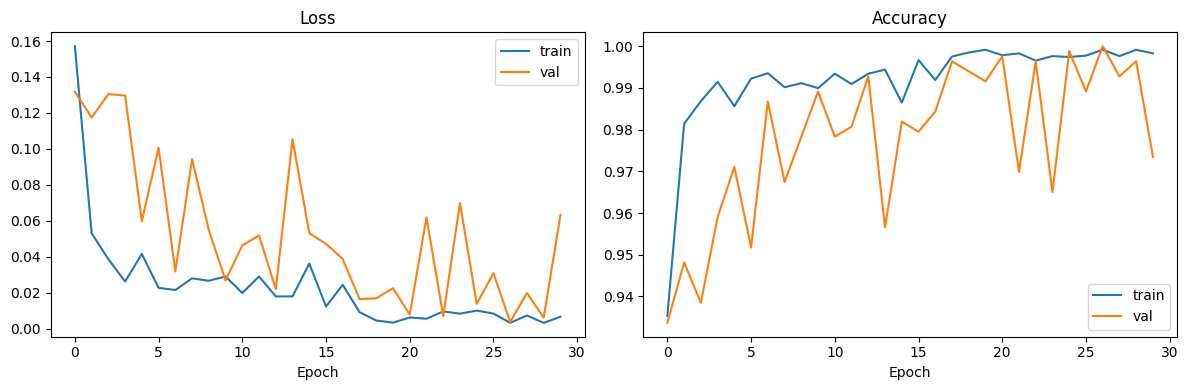

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Load best checkpoint and evaluate on test set

C:\Users\anish\AppData\Local\Temp\ipykernel_26600\3000918205.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device

Test accuracy: 0.9861660079051383
Test ROC-AUC: 0.9971309419290103

               precision    recall  f1-score   support

    fractured       1.00      0.97      0.99       238
not fractured       0.97      1.00      0.99       268

     accuracy                           0.99       506
    macro avg       0.99      0.99      0.99       506
 weighted avg       0.99      0.99      0.99       506



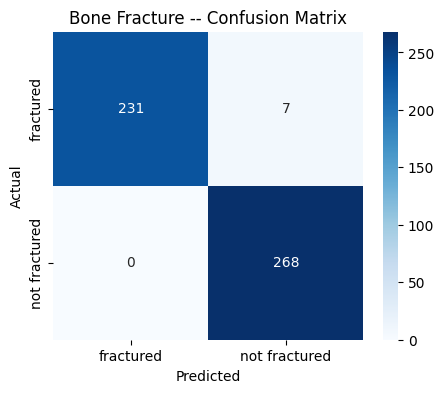

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import numpy as np

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

print("Test accuracy:", (np.array(all_preds) == np.array(all_labels)).mean())
if NUM_CLASSES == 2:
    positive_probs = [p[1] for p in all_probs]
    print("Test ROC-AUC:", roc_auc_score(all_labels, positive_probs))
print()
print(classification_report(all_labels, all_preds, target_names=class_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Bone Fracture -- Confusion Matrix")
plt.show()

## Notes

- **Checkpoint saved to:** `models/checkpoints/bone_fracture_efficientnet_b0.pt` -- sync to
  Drive same as your other specialists.
- **This is the 7th specialist** -- once you're happy with the numbers, this is the one that
  unlocks uncommenting `bone_fracture` in Router Stage 2's `MODALITY_SOURCES` and retraining
  the router as a 7-class problem.
- **Explainability (Grad-CAM) deliberately omitted** here, same as your other specialist
  notebooks -- planned as a separate later addition applied uniformly across all specialists,
  not per-notebook.
